<a href="https://colab.research.google.com/github/Johamercado/simulacion-album-mundial/blob/main/Trabajo_de_Simulaci%C3%B3n_2_%C3%A1lbum_del_mundial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Integrantes:** Camila Delgado (A), Juan Figueroa (A), Mariana La Rosa Saubidet (A), Johanna Mercado (A), Viviana Reverberi (A)

In [5]:
# Simulación y cálculo del promedio estimado

import numpy as np
import random as rd

# Semilla con DNI
rd.seed(38832704)

# Parámetros del álbum real
figus_total = 860
figus_paquete = 5
N = 500  # Cantidad de repeticiones para la simulación de Monte Carlo

def cuantos_paquetes(figus_total, figus_paquete):
    # Simulamos ir abriendo paquetes hasta llenar el álbum
    album = set()
    paquetes = 0
    todas_las_figus = list(range(1, figus_total + 1))

    # Continuamos abriendo paquetes hasta conseguir las 860 figuritas
    while len(album) < figus_total:
        paquetes += 1
        # 5 figuritas distintas por sobre
        sobre = rd.sample(todas_las_figus, figus_paquete)
        album.update(sobre)

    return paquetes

# Corremos las 500 repeticiones
muestras = [cuantos_paquetes(figus_total, figus_paquete) for _ in range(N)]

# Calculamos e imprimimos el promedio estimado
promedio_estimado = np.mean(muestras)
print(f"Promedio estimado: {promedio_estimado:.2f}")

Promedio estimado: 1256.68


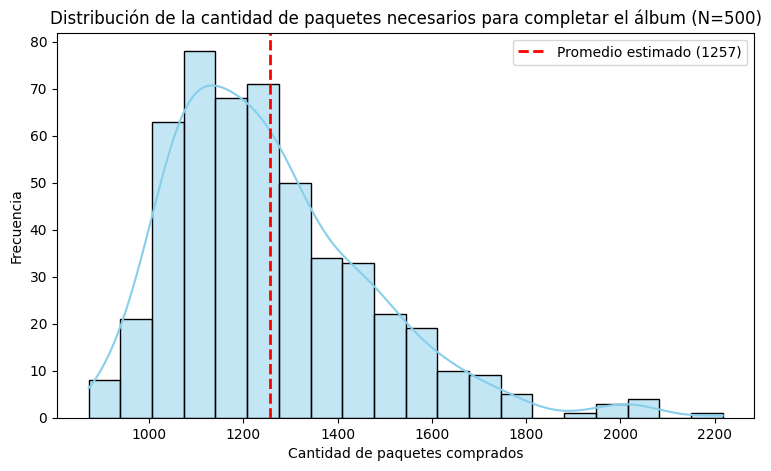

In [4]:
# Histograma de la cantidad de paquetes

import matplotlib.pyplot as plt
import seaborn as sns

# Visualización de la distribución de paquetes necesarios
plt.figure(figsize=(9, 5))
sns.histplot(muestras, kde=True, color='skyblue', edgecolor='black')
plt.axvline(promedio_estimado, color='red', linestyle='--', linewidth=2, label=f'Promedio estimado ({promedio_estimado:.0f})')
plt.title('Distribución de la cantidad de paquetes necesarios para completar el álbum (N=500)', fontsize=12)
plt.xlabel('Cantidad de paquetes comprados')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

In [11]:
# Respuesta obligatoria: promedio estimado y valor teorico lado a lado
H_n = sum(1.0 / i for i in range(1, figus_total + 1))
teorico = (figus_total * H_n) / figus_paquete

print(f"Promedio estimado: {promedio_estimado:.2f} paquetes | Valor teórico: {teorico:.2f} paquetes\n")

# ---------------------------------------------------------
# Extra: Comparativa de estrategias basandonos en la nota de Federico Holik
# ---------------------------------------------------------
import pandas as pd

# Simulamos llenar el album entre un grupo de 8 amigos que comparten repetidas
def simular_grupo(amigos=8):
    album_grupal = {i: 0 for i in range(1, figus_total + 1)}
    completos = 0
    sobres_totales = 0
    figus = list(range(1, figus_total + 1))

    while completos < figus_total:
        sobres_totales += 1
        sobre = rd.sample(figus, figus_paquete)
        for f in sobre:
            album_grupal[f] += 1
            if album_grupal[f] == amigos:
                completos += 1

    return sobres_totales / amigos

# Corremos algunas simulaciones del grupo de 8
muestras_grupo = [simular_grupo(8) for _ in range(50)]
prom_grupo = np.mean(muestras_grupo)

# Estrategia 3: Comprar una cantidad fija inicial (ej. 200 sobres) y el resto cambiar
sobres_fijos = 200

# Estimamos repetidas y costos aprox ($1500 por paquete)
precio = 1500

datos = [
    {
        "Estrategia": "1. Individual (comprando hasta llenar)",
        "Paquetes por persona": round(promedio_estimado),
        "Total figuritas": round(promedio_estimado * figus_paquete),
        "% Repetidas": f"{((promedio_estimado * 5 - 860) / (promedio_estimado * 5)) * 100:.1f}%",
        "Gasto estimado": f"${round(promedio_estimado * precio):,}"
    },
    {
        "Estrategia": "2. Grupo de 8 amigos (intercambio total)",
        "Paquetes por persona": round(prom_grupo),
        "Total figuritas": round(prom_grupo * figus_paquete),
        "% Repetidas": f"{((prom_grupo * 5 - 860) / (prom_grupo * 5)) * 100:.1f}%",
        "Gasto estimado": f"${round(prom_grupo * precio):,}"
    },
    {
        "Estrategia": "3. Inversion inicial (200 sobres + canje)",
        "Paquetes por persona": sobres_fijos,
        "Total figuritas": sobres_fijos * figus_paquete,
        "% Repetidas": f"{((sobres_fijos * 5 - 650) / (sobres_fijos * 5)) * 100:.1f}%",
        "Gasto estimado": f"${sobres_fijos * precio:,}"
    }
]

df_estrategias = pd.DataFrame(datos)
display(df_estrategias)

Promedio estimado: 1256.68 paquetes | Valor teórico: 1261.57 paquetes



,Estrategia,Paquetes por persona,Total figuritas,% Repetidas,Gasto estimado
0,1. Individual (comprando hasta llenar),1257,6283,86.3%,"$1,885,014"
1,2. Grupo de 8 amigos (intercambio total),429,2146,59.9%,"$643,740"
2,3. Inversion inicial (200 sobres + canje),200,1000,35.0%,"$300,000"


In [9]:
# Celda de autochequeo provista (NO MODIFICAR)

import statistics

FIGUS_TOTAL, FIGUS_PAQUETE = 860, 5

# Para control interno mío, DP #
def valor_teorico(figus_total=FIGUS_TOTAL, figus_paquete=FIGUS_PAQUETE):
    H = sum(1.0/i for i in range(1, figus_total+1))
    return figus_total * H / figus_paquete

def autochequeo(muestras):
    teo = valor_teorico()
    N = len(muestras)
    est = statistics.mean(muestras)
    relerr = abs(est - teo) / teo
    ok_N = N >= 300
    ok_err = relerr < 0.06
    if ok_N and ok_err:
        print(f"OK - promedio estimado {est:.0f} paquetes vs teorico {teo:.0f} "
              f"(error {relerr*100:.1f}% < 6%); N={N}")
    else:
        print("REVISAR:")
        if not ok_N:
            print(f"   - Usaste N={N} repeticiones; para que el promedio quede estable, corre con N>=500.")
        if not ok_err:
            print(f"   - Tu promedio dio {est:.0f} y el teorico es {teo:.0f} (error {relerr*100:.0f}%).")
            if est > teo * 3:
                print("     Parece que contaste FIGURITAS en vez de PAQUETES (hay 5 por paquete): conta paquetes o divide por 5.")
            else:
                print("     Revisa el tamano del album (debe ser 860) y que sumes 1 por cada paquete comprado hasta completar.")

# Ejecutamos la verificación
autochequeo(muestras)

OK - promedio estimado 1257 paquetes vs teorico 1262 (error 0.4% < 6%); N=500
